In [49]:
#python libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [50]:
df=pd.read_csv("/content/AB_NYC_2019.csv")

In [51]:
df.shape

(48895, 16)

In [52]:
df.columns

Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')

In [53]:
df.dtypes

,0
id,int64
name,object
host_id,int64
host_name,object
neighbourhood_group,object
neighbourhood,object
latitude,float64
longitude,float64
room_type,object
price,int64


In [65]:
df.head()

,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
0,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,0.21,6,365
1,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,0.38,2,355
2,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,0.00,1,365
3,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,4.64,1,194
4,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,0.10,1,0


In [54]:
df.select_dtypes(include=['number'])

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,2787,40.64749,-73.97237,149,1,9,0.21,6,365
1,2595,2845,40.75362,-73.98377,225,1,45,0.38,2,355
2,3647,4632,40.80902,-73.94190,150,3,0,NaN,1,365
3,3831,4869,40.68514,-73.95976,89,1,270,4.64,1,194
4,5022,7192,40.79851,-73.94399,80,10,9,0.10,1,0
...,...,...,...,...,...,...,...,...,...,...
48890,36484665,8232441,40.67853,-73.94995,70,2,0,NaN,2,9
48891,36485057,6570630,40.70184,-73.93317,40,4,0,NaN,2,36
48892,36485431,23492952,40.81475,-73.94867,115,10,0,NaN,1,27
48893,36485609,30985759,40.75751,-73.99112,55,1,0,NaN,6,2


In [55]:
df.select_dtypes(include=['object'])

,name,host_name,neighbourhood_group,neighbourhood,room_type,last_review
0,Clean & quiet apt home by the park,John,Brooklyn,Kensington,Private room,2018-10-19
1,Skylit Midtown Castle,Jennifer,Manhattan,Midtown,Entire home/apt,2019-05-21
2,THE VILLAGE OF HARLEM....NEW YORK !,Elisabeth,Manhattan,Harlem,Private room,NaN
3,Cozy Entire Floor of Brownstone,LisaRoxanne,Brooklyn,Clinton Hill,Entire home/apt,2019-07-05
4,Entire Apt: Spacious Studio/Loft by central park,Laura,Manhattan,East Harlem,Entire home/apt,2018-11-19
...,...,...,...,...,...,...
48890,Charming one bedroom - newly renovated rowhouse,Sabrina,Brooklyn,Bedford-Stuyvesant,Private room,NaN
48891,Affordable room in Bushwick/East Williamsburg,Marisol,Brooklyn,Bushwick,Private room,NaN
48892,Sunny Studio at Historical Neighborhood,Ilgar & Aysel,Manhattan,Harlem,Entire home/apt,NaN
48893,43rd St. Time Square-cozy single bed,Taz,Manhattan,Hell's Kitchen,Shared room,NaN


In [56]:
missing=df.isnull().sum()
print(missing)

id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64


In [57]:
missing_percent = (missing / len(df)) * 100
print(missing_percent)

id                                 0.000000
name                               0.032723
host_id                            0.000000
host_name                          0.042949
neighbourhood_group                0.000000
neighbourhood                      0.000000
latitude                           0.000000
longitude                          0.000000
room_type                          0.000000
price                              0.000000
minimum_nights                     0.000000
number_of_reviews                  0.000000
last_review                       20.558339
reviews_per_month                 20.558339
calculated_host_listings_count     0.000000
availability_365                   0.000000
dtype: float64


In [58]:
df=df.drop(columns=['last_review'])
print(df.columns)

Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'reviews_per_month',
       'calculated_host_listings_count', 'availability_365'],
      dtype='object')


In [59]:
print(df[df["reviews_per_month"].isnull()][["number_of_reviews", "reviews_per_month"]].head(10))

     number_of_reviews  reviews_per_month
2                    0                NaN
19                   0                NaN
26                   0                NaN
36                   0                NaN
38                   0                NaN
193                  0                NaN
204                  0                NaN
260                  0                NaN
265                  0                NaN
267                  0                NaN


In [60]:
df["reviews_per_month"] = df["reviews_per_month"].fillna(0)

In [61]:
print(df.columns)

Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'reviews_per_month',
       'calculated_host_listings_count', 'availability_365'],
      dtype='object')


In [62]:
df = df.drop(columns=["id","name","host_id","host_name"])
print(df.columns)

Index(['neighbourhood_group', 'neighbourhood', 'latitude', 'longitude',
       'room_type', 'price', 'minimum_nights', 'number_of_reviews',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')


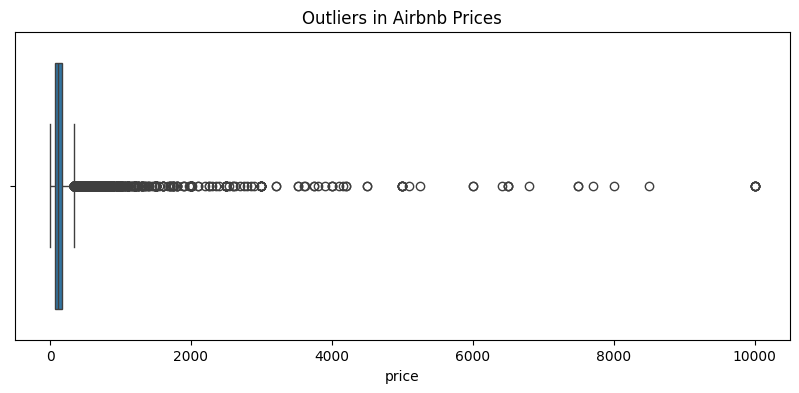

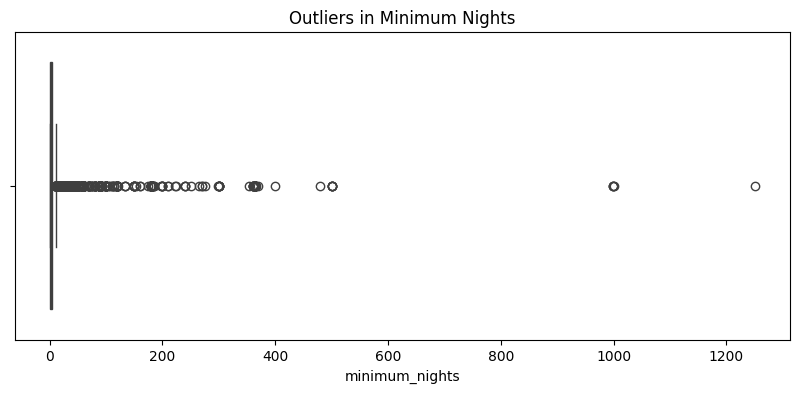

In [63]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df["price"])
plt.title("Outliers in Airbnb Prices")
plt.show()

plt.figure(figsize=(10, 4))
sns.boxplot(x=df["minimum_nights"])
plt.title("Outliers in Minimum Nights")
plt.show()

In [64]:
# Find the 95th percentile for both columns
price_limit = df["price"].quantile(0.95)
nights_limit = df["minimum_nights"].quantile(0.95)

print("95th percentile of price:", price_limit)
print("95th percentile of minimum nights:", nights_limit)

# Keep only rows within both limits
df = df[
    (df["price"] <= price_limit) &
    (df["minimum_nights"] <= nights_limit)
]

print("Dataset shape after removing outliers:", df.shape)

95th percentile of price: 355.0
95th percentile of minimum nights: 30.0
Dataset shape after removing outliers: (45759, 11)


In [66]:
print("Unique neighbourhoods:", df["neighbourhood"].nunique())
print("Unique neighbourhood groups:", df["neighbourhood_group"].nunique())

Unique neighbourhoods: 219
Unique neighbourhood groups: 5


In [67]:
df = df.drop(columns=["neighbourhood"])

In [68]:
df = pd.get_dummies(df,columns=["neighbourhood_group", "room_type"],drop_first=True,dtype=int)

In [69]:
print(df.columns)

Index(['latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365', 'neighbourhood_group_Brooklyn',
       'neighbourhood_group_Manhattan', 'neighbourhood_group_Queens',
       'neighbourhood_group_Staten Island', 'room_type_Private room',
       'room_type_Shared room'],
      dtype='object')


In [71]:
X = df.drop(columns=["price"])
y = df["price"]

In [72]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (45759, 13)
y shape: (45759,)


In [73]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (36607, 13)
X_test: (9152, 13)
y_train: (36607,)
y_test: (9152,)


In [74]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [75]:
y_pred = model.predict(X_test)

print("First 10 actual prices:")
print(y_test.head(10).values)

print("\nFirst 10 predicted prices:")
print(y_pred[:10])

First 10 actual prices:
[132 250 350 250 199 139 150  55 184 129]

First 10 predicted prices:
[173.31999192 157.35088508 173.11463763 182.65747453 186.31011596
 165.57173509 128.75527424  59.73992377 191.65680481  99.05073498]


In [76]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("R² Score:", r2)
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)

R² Score: 0.47082773500021025
MAE: 38.5408749155387
MSE: 2834.959378892661
RMSE: 53.244336589844565


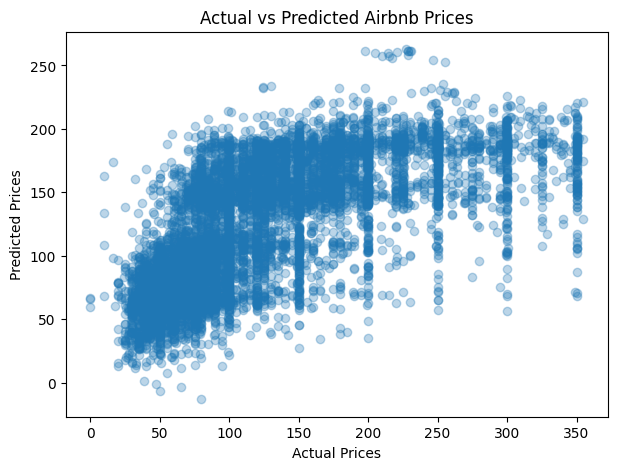

In [78]:
# scatter plot of Actual Prices vs. Predicted Prices

plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual vs Predicted Airbnb Prices")
plt.show()

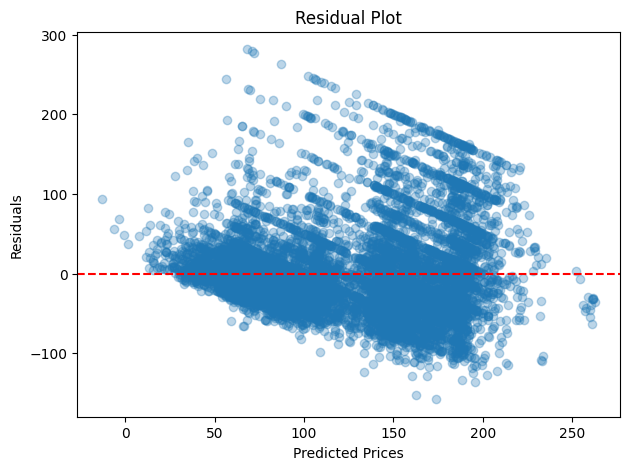

In [79]:
residuals = y_test - y_pred

plt.figure(figsize=(7, 5))
plt.scatter(y_pred, residuals, alpha=0.3)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Predicted Prices")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

In [ ]:
from sklearn.metrics import mean_absolute_error

results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

median_price = results["Actual"].median()

cheap = results[results["Actual"] <= median_price]
expensive = results[results["Actual"] > median_price]

print("Median actual price:", median_price)
print("Cheap listings MAE:", mean_absolute_error(cheap["Actual"], cheap["Predicted"]))
print("Expensive listings MAE:", mean_absolute_error(expensive["Actual"], expensive["Predicted"]))

Median actual price: 100.0
Cheap listings MAE: 29.02766370088442
Expensive listings MAE: 48.57963069763177
